# Evaluation: which strawberry model should we trust?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/03_Evaluation/notebooks/TD2_strawberry_student.ipynb)

In Foundations, one small decision tree predicted Strawberry or
NON-Strawberry from eight features. Here we use the same classification
task to compare a small tree, a deep tree and a random forest. We ask
whether better results on training samples also mean better results
on samples excluded from training.

All code is supplied. Run the cells from top to bottom with their ▶ buttons.
Read the explanation above each cell and inspect its output. To answer a
question, double-click its Your answer text cell and write in words.

Click Open in Colab above to start this notebook. Use the standard CPU runtime.

## 1. Look at the measurements

Each sample is one recorded measurement of a fruit purée. Its infrared
spectrum contains 235 signal values measured at different wavenumbers.
A wavenumber identifies a position along the infrared spectrum.

A feature is a number describing a sample. For now, each measured signal
at a particular wavenumber is one feature: 235 features per sample.
The recorded label gives the known class and is kept separate from the features.

Strawberry is one class. NON-Strawberry includes other fruit purées and
adulterated strawberry mixtures. The file does not identify the particular
adulterant or its amount for each sample.

The first cell loads the tools: `pd` works with tables and `plt` draws plots.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

Read the public data file. Its first row contains sample labels, so
`header=None` keeps that row in the table. The fixed address selects the
same version of the source file throughout the strawberry practicals.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/zwbben/SpectroscopyData/"
    "4db9b8168fac1185973d1e7888d51f7f33f94857/MIR_Fruit_purees.csv"
)
raw_data = pd.read_csv(DATA_URL, header=None)

Here is the table as it was read. Row 0 gives the sample labels. Column 0
gives the wavenumbers, starting below the word Wavenumbers. Each remaining
column contains one sample's spectrum. The table has 983 sample columns.
Only the first and last parts of this large table are displayed.

In [3]:
raw_data

,0,1,2,3,4,5,6,7,8,9,...,974,975,976,977,978,979,980,981,982,983
0,Wavenumbers,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,...,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry
1,899.327,0.002805507,0.00263738,0.002415868,0.00234529,0.002302508,0.002513791,0.002105496,0.002018384,0.002153632,...,0.002539315,0.002568574,0.002723227,0.002542207,0.00262688,0.002631082,0.002730378,0.002712845,0.002696845,0.002789428
2,903.187,0.002731944,0.002638345,0.002479677,0.002291981,0.00234218,0.002488288,0.002078167,0.0019987,0.002165058,...,0.002507276,0.002568594,0.002714211,0.002538884,0.002629394,0.002650873,0.002838751,0.0027786,0.00290547,0.003039869
3,907.047,0.00266115,0.002651382,0.002510657,0.002248641,0.00234953,0.00247745,0.002077299,0.001944556,0.002191274,...,0.002482726,0.002541337,0.002739762,0.002574314,0.002618641,0.002696092,0.002999267,0.002877433,0.003277223,0.003358926
4,910.907,0.00265707,0.002757381,0.002611341,0.002303143,0.002419224,0.002542069,0.002154436,0.001963826,0.002274862,...,0.002562686,0.002598623,0.002860805,0.002663535,0.002713847,0.002809383,0.003258967,0.003084947,0.003711203,0.003796026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
231,1787.124,8.70401E-05,-5.50734E-06,6.22218E-05,7.52099E-05,9.87553E-05,5.40501E-05,6.37965E-05,0.000101614,8.11771E-05,...,4.1971E-06,8.43141E-06,8.41589E-06,5.40847E-06,1.21E-05,-1.26769E-06,-7.71062E-07,6.59038E-06,-9.43563E-06,-2.02171E-05
232,1790.984,4.58481E-05,1.84089E-06,3.11324E-05,4.29712E-05,5.37301E-05,3.14769E-05,4.30507E-05,6.35453E-05,5.52157E-05,...,6.96074E-06,1.84257E-05,1.02528E-05,6.93735E-06,1.21853E-05,2.9724E-06,2.04995E-07,6.81436E-06,-5.09051E-06,-5.91353E-06
233,1794.844,1.08289E-05,9.65908E-06,8.81474E-06,2.10302E-05,1.97074E-05,1.60126E-05,2.71518E-05,3.76145E-05,3.25956E-05,...,1.43265E-05,1.41472E-05,1.49764E-05,1.29431E-05,9.70352E-06,7.40502E-06,6.58678E-06,1.21564E-05,-2.41264E-06,-5.06714E-06
234,1798.704,9.39817E-06,5.07603E-06,7.15697E-06,7.53529E-06,1.17139E-05,8.13114E-06,1.19344E-05,1.46512E-05,1.35374E-05,...,1.08665E-05,1.1123E-05,1.0027E-05,9.52043E-06,6.39644E-06,7.76824E-06,5.12522E-06,1.28675E-05,1.04989E-06,-1.83347E-06


Separate the labels from the numbers. Because each source column contains
both words and numbers, the values were initially read as text.
`astype(float)` converts the numerical part to numbers, once.

`iloc` selects rows or columns by their position. `.T` swaps rows and
columns so that each row of `spectra` becomes one sample. The last line
uses the wavenumbers to name its columns.

In [4]:
labels = raw_data.iloc[0, 1:]
numeric_data = raw_data.iloc[1:].astype(float)
spectra = numeric_data.iloc[:, 1:].T
spectra.columns = numeric_data.iloc[:, 0]

Two records have exactly the same measurements but opposite labels.
We leave both out because the file cannot tell us which label is right.
`~` means “not”: keep the rows that are not repeated. This leaves 981
spectra: 350 Strawberry and 631 NON-Strawberry.

In [5]:
repeated = spectra.duplicated(keep=False)
spectra = spectra.loc[~repeated]
labels = labels.loc[~repeated]
print("Samples kept:", len(spectra))
print(labels.value_counts())

Samples kept: 981
0
NON-Strawberry    631
Strawberry        350
Name: count, dtype: int64


The measurements now have one sample per row and one wavenumber per column.
Show the first five rows and six measured wavenumbers. Each entry is that
sample's supplied infrared signal at that wavenumber. The row numbers
identify positions in the source file, not physical specimen IDs.

In [6]:
spectra.iloc[:5, :6]

,899.327,903.187,907.047,910.907,914.767,918.627
1,0.002806,0.002732,0.002661,0.002657,0.002699,0.002762
2,0.002637,0.002638,0.002651,0.002757,0.003000,0.003313
3,0.002416,0.002480,0.002511,0.002611,0.002802,0.003031
4,0.002345,0.002292,0.002249,0.002303,0.002466,0.002642
5,0.002303,0.002342,0.002350,0.002419,0.002561,0.002737


### Draw two example spectra

Select the first recorded example from each class. Each line below joins
its 235 measured signals. These are two individual examples, not class
averages. Similar-looking spectra can still have different labels.
The CSV does not establish absolute physical units for the supplied signal.

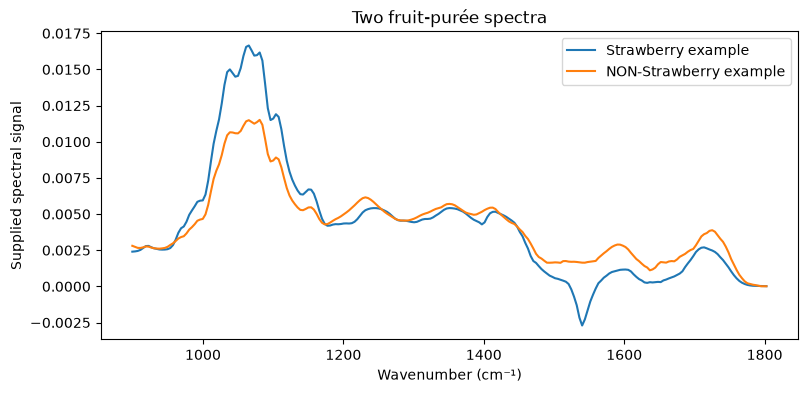

In [7]:
strawberry_id = labels.loc[labels == "Strawberry"].index[0]
other_id = labels.loc[labels == "NON-Strawberry"].index[0]
plt.figure(figsize=(9, 4))
plt.plot(spectra.columns, spectra.loc[strawberry_id], label="Strawberry example")
plt.plot(spectra.columns, spectra.loc[other_id], label="NON-Strawberry example")
plt.xlabel("Wavenumber (cm⁻¹)")
plt.ylabel("Supplied spectral signal")
plt.title("Two fruit-purée spectra")
plt.legend()
plt.show()

## 2. Describe each spectrum with eight numbers

Instead of giving the model all 235 signals, we divide the spectrum into
eight fixed windows and take the average signal in each window. These
eight averages become our new features, B1 to B8. For example, B1 averages
the signal between 899 and 1012 cm⁻¹. It is not a sugar concentration.

Each line below selects one range with `loc` and averages it for every
sample with `mean(axis=1)`. `head()` shows five rows; `round(4)` rounds
only the display. The original spectra remain available in `spectra`.

In [8]:
features = pd.DataFrame(index=spectra.index)
features["B1"] = spectra.loc[:, 899:1012].mean(axis=1)
features["B2"] = spectra.loc[:, 1012:1125].mean(axis=1)
features["B3"] = spectra.loc[:, 1125:1238].mean(axis=1)
features["B4"] = spectra.loc[:, 1238:1351].mean(axis=1)
features["B5"] = spectra.loc[:, 1351:1464].mean(axis=1)
features["B6"] = spectra.loc[:, 1464:1577].mean(axis=1)
features["B7"] = spectra.loc[:, 1577:1690].mean(axis=1)
features["B8"] = spectra.loc[:, 1690:1803].mean(axis=1)
features.head().round(4)

,B1,B2,B3,B4,B5,B6,B7,B8
1,0.0035,0.0097,0.0052,0.0051,0.0049,0.0019,0.0020,0.0019
2,0.0046,0.0149,0.0052,0.0043,0.0047,0.0006,-0.0003,0.0002
3,0.0041,0.0098,0.0050,0.0048,0.0047,0.0019,0.0022,0.0017
4,0.0037,0.0107,0.0055,0.0052,0.0045,0.0009,0.0015,0.0022
5,0.0038,0.0104,0.0057,0.0053,0.0044,0.0008,0.0012,0.0024


Draw the same two samples again, now using only their eight window means.
Each point represents one window's average. Compare these lines with the
original spectra: broad patterns remain, while individual peaks are lost.
The models below receive these eight values, not the original 235 signals.

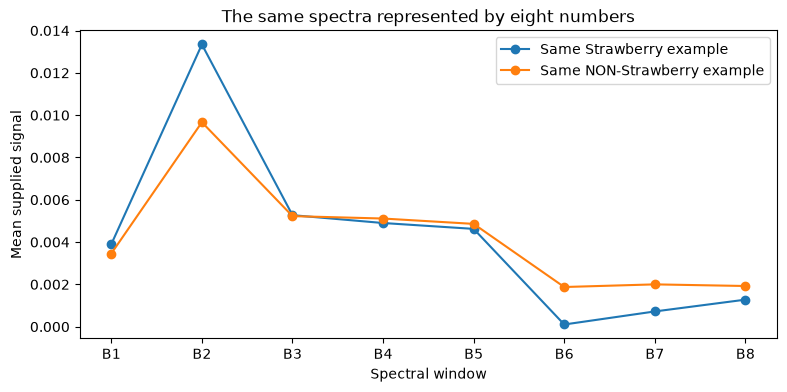

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(features.columns, features.loc[strawberry_id], marker="o", label="Same Strawberry example")
plt.plot(features.columns, features.loc[other_id], marker="o", label="Same NON-Strawberry example")
plt.xlabel("Spectral window")
plt.ylabel("Mean supplied signal")
plt.title("The same spectra represented by eight numbers")
plt.legend()
plt.show()

### Stop and explain 1

What information is given to the model, and what should it predict?
Why are the two identically measured but differently labelled records left out?

Your answer:

Write your answer here in words.

## 3. Give three sets of samples different jobs

- Training: teach each model.
- Validation: compare models and choose one.
- Test: check the chosen model after the choice is fixed.

First, keep 20% aside for testing. Then keep a quarter of the remaining
samples for validation. This gives about 60% training, 20% validation and
20% test samples. Every model will use exactly the same groups.

In the code, X means the eight feature columns and y means the
recorded labels. The endings `_train`, `_validation` and `_test` tell us
which sample group a table belongs to.

`X_development` and `y_development` hold the 784 samples used for training
in Foundations. Here we divide them into 588 training and 196 validation
samples. The 197 test samples stay the same. The small tree therefore
learns from fewer examples than before, so its results can change.

In [10]:
X_development, X_test, y_development, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25,
    random_state=42, stratify=y_development
)
print("Training:", len(X_train))
print("Validation:", len(X_validation))
print("Test:", len(X_test))

Training: 588
Validation: 196
Test: 197


The test group is the same one used in Foundations. We keep it out of model
comparison here, but its reuse is a classroom exercise rather than new
independent evidence. The file also lacks IDs for physical specimens and batches.

### Stop and explain 2

Which samples teach the models, which help us choose, and which are used
at the end? Why should all models use the same training and validation samples?

Your answer:

Write your answer here in words.

## 4. Compare a small and a deep tree

Start with a tree that asks at most two questions along a path. `fit`
learns from the training data. For these classifiers, `score` gives
accuracy on the named data: the fraction of predictions matching the labels.
The two scores below answer different questions: how well does it fit the
training examples, and how well does it predict validation examples?

An accuracy of 0.90 means that 90% of the samples were classified correctly.

In [11]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
small_tree.fit(X_train, y_train)
small_training = small_tree.score(X_train, y_train)
small_validation = small_tree.score(X_validation, y_validation)
print("Small tree, training:", round(small_training, 3))
print("Small tree, validation:", round(small_validation, 3))

Small tree, training: 0.838
Small tree, validation: 0.827


Now remove the depth limit. The deep tree can keep adding questions to
separate training examples. Only the model's complexity changes; the
measurements, labels and sample groups stay the same.

Overfitting means learning details that help on the training samples
but do not help as much on other samples. A growing gap between
training and validation accuracy is a warning sign.

In [12]:
deep_tree = DecisionTreeClassifier(random_state=42)
deep_tree.fit(X_train, y_train)
deep_training = deep_tree.score(X_train, y_train)
deep_validation = deep_tree.score(X_validation, y_validation)
print("Deep tree, training:", round(deep_training, 3))
print("Deep tree, validation:", round(deep_validation, 3))

Deep tree, training: 1.0
Deep tree, validation: 0.842


### Stop and explain 3

How much does training accuracy improve when the tree becomes deeper?
Does validation accuracy improve by as much? Explain what this suggests
about overfitting.

Your answer:

Write your answer here in words.

## 5. Add a random forest

A random forest combines many trees instead of relying on one. Here it uses
100 trees. The code follows exactly the same steps: create, fit, then score
on training and validation samples.

In [13]:
forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_training = forest.score(X_train, y_train)
forest_validation = forest.score(X_validation, y_validation)
print("Forest, training:", round(forest_training, 3))
print("Forest, validation:", round(forest_validation, 3))

Forest, training: 1.0
Forest, validation: 0.898


Put the three pairs of scores in one table. Look especially at validation
accuracy: these samples were excluded from every model's training.

In [14]:
results = pd.DataFrame({
    "Model": ["Small tree", "Deep tree", "Forest"],
    "Training": [small_training, deep_training, forest_training],
    "Validation": [small_validation, deep_validation, forest_validation]
})
results = results.set_index("Model")
results.round(3)

,Training,Validation
Model,,
Small tree,0.838,0.827
Deep tree,1.000,0.842
Forest,1.000,0.898


The bars show the same numbers. A large gap between a model's training and
validation bars is a warning. Also compare with a simple rule that always
predicts NON-Strawberry, the most common training class.

A forest can also fit its training samples very closely. Its validation
accuracy still needs to be checked; combining trees does not remove that need.

In the comparison rule, `==` checks whether a label matches NON-Strawberry;
`mean()` gives the fraction of matching labels.

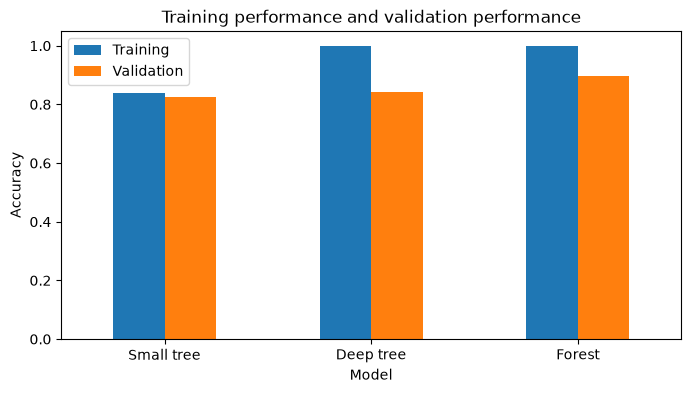

Always NON-Strawberry, validation: 0.643


In [15]:
results.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Training performance and validation performance")
plt.show()
baseline_validation = (y_validation == "NON-Strawberry").mean()
print("Always NON-Strawberry, validation:", round(baseline_validation, 3))

### Stop and explain 4

Which model has the highest validation accuracy? Does it beat the constant
NON-Strawberry rule? Explain why the training score alone cannot choose the winner.

Your answer:

Write your answer here in words.

## 6. Choose first, then test

Choose the model with the highest validation accuracy. `idxmax` returns
the name beside the largest validation number. The first line links each
name to its trained model; `models[chosen_name]` retrieves that model.
No model is retrained here.

In [16]:
models = {"Small tree": small_tree, "Deep tree": deep_tree, "Forest": forest}
chosen_name = results["Validation"].idxmax()
chosen_model = models[chosen_name]
print("Chosen using validation samples:", chosen_name)

Chosen using validation samples: Forest


Now apply that fixed model to the test features. The reference test labels
are used only to check the predictions. Keep the choice fixed after this
point; changing models to improve the test score would turn testing into
another round of model selection.

In the confusion matrix, rows are reference labels and columns are predictions.
The diagonal contains correct predictions. A NON-Strawberry sample predicted
Strawberry is a false acceptance; the opposite error is a false rejection.

Test accuracy: 0.944


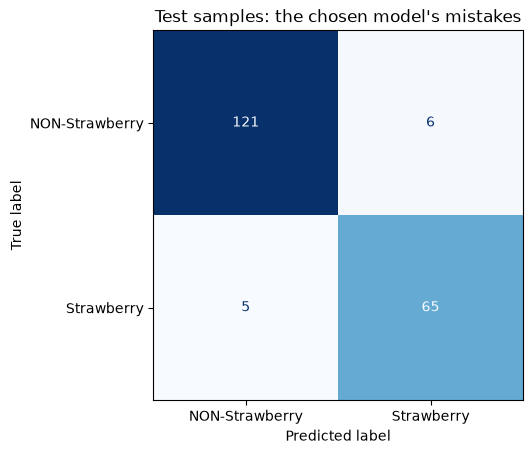

In [17]:
predictions = chosen_model.predict(X_test)
test_accuracy = accuracy_score(y_test, predictions)
print("Test accuracy:", round(test_accuracy, 3))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["NON-Strawberry", "Strawberry"],
    cmap="Blues", colorbar=False
)
plt.title("Test samples: the chosen model's mistakes")
plt.show()

### Stop and explain 5

How many false acceptances and false rejections occurred? Why would it be
misleading to try different settings now and report only the best test score?

Your answer:

Write your answer here in words.

## 7. Explain the comparison

Training teaches a model; validation helps choose between models;
testing checks the fixed choice. A large training/validation gap warns
about overfitting. One split and one dataset cannot establish how the
model will perform on every future supplier or adulterant.

Next, Applications keeps the same eight features and test group but
changes the question: which measurements are unusual compared with
the labelled Strawberry training samples?

### Stop and explain 6

Write three sentences for the laboratory manager: what the small-versus-deep
comparison showed, which model was chosen and how it performed on testing,
and one limitation before using it on new products.

Your answer:

Write your answer here in words.

## Data and reuse

The dataset contains measured infrared spectra of fruit purées. The
original file has 983 spectra; 981 remain after excluding the conflicting
pair. NON-Strawberry includes other fruits and adulterated mixtures.
The file does not give separate adulterant, supplier or replicate IDs.
These exercises cannot establish product purity or identify an adulterant.

- Holland, Kemsley and Wilson (1998), *Use of Fourier transform infrared
  spectroscopy and partial least squares regression for the detection of
  adulteration of strawberry purées*.
  [Original study](https://research-portal.uea.ac.uk/en/publications/use-of-fourier-transform-infrared-spectroscopy-and-partial-least-/).
- Shu, Tang, Zhang and Zheng (2019),
  [dataset deposition](https://doi.org/10.17632/frrv2yd9rg.1), version 1.
  Data licence: [CC BY-NC 3.0](https://creativecommons.org/licenses/by-nc/3.0/).
  The data licence is separate from the course-code licence.

The fixed spectral windows are teaching summaries, not selected chemical
markers. This exercise does not reproduce the original paper's analysis.